### Proyecto 2 – Regresión Lineal Múltiple

Introducción

En este proyecto desarrollamos un modelo de Regresión Lineal Múltiple utilizando Python y herramientas de análisis de datos y aprendizaje automático.

El objetivo es construir un modelo capaz de estimar el precio de una propiedad por unidad de superficie a partir de distintas características relacionadas con su ubicación y sus alrededores.

Para realizar el análisis utilizamos el conjunto de datos "Real Estate Valuation", que contiene información sobre propiedades inmobiliarias. Seleccionamos cinco variables predictoras:

* Antigüedad de la propiedad.

* Distancia a la estación de MRT más cercana.

* Cantidad de comercios cercanos.

* Latitud.

* Longitud.

La variable que buscamos predecir es el precio por unidad de superficie.

A lo largo del trabajo realizamos la carga y exploración de los datos, la selección de variables, su conversión a estructuras matriciales y la división del conjunto de datos en entrenamiento y prueba. Posteriormente, entrenamos un modelo de Regresión Lineal Múltiple y evaluamos su rendimiento mediante distintas métricas, como R², MSE y RMSE.

Finalmente, analizamos los coeficientes del modelo para identificar qué variables tienen mayor influencia relativa en las predicciones y comparamos los resultados obtenidos con los datos de entrenamiento y de prueba.

Nuestro propósito es comprender cómo un modelo de aprendizaje automático puede utilizar datos reales para realizar estimaciones y evaluar qué tan buenas son sus predicciones.

### Instalación e importación de bibliotecas

In [1]:
# Instalamos ucimlrepo, que permite descargar el dataset desde UCI por su ID.
!pip install ucimlrepo

In [2]:
# Usamos pandas para las tablas, NumPy para los cálculos y Matplotlib para los gráficos.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Importamos la función que busca el dataset por su ID en el repositorio UCI.
from ucimlrepo import fetch_ucirepo
# Importamos las herramientas para dividir los datos, entrenar la regresión y evaluar las predicciones.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## Carga del Dataset

In [3]:
# Cargamos el dataset Real Estate Valuation de UCI, identificado con el número 477.
datos = fetch_ucirepo(id=477)

# Guardamos los seis predictores originales en X y el precio por unidad de superficie en y.
X = datos.data.features
y = datos.data.targets

# Miramos las primeras cinco filas de X para reconocer sus columnas y valores.
X.head()

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
0,2012.917,32.0,84.87882,10,24.98298,121.54024
1,2012.917,19.5,306.59470,9,24.98034,121.53951
2,2013.583,13.3,561.98450,5,24.98746,121.54391
3,2013.500,13.3,561.98450,5,24.98746,121.54391
4,2012.833,5.0,390.56840,5,24.97937,121.54245


In [4]:
# shape devuelve (filas, columnas). Cada fila representa un registro y el precio ocupa una columna en y.
print("Dimensiones de X:", X.shape)
print("Dimensiones de Y:", y.shape)

# Revisamos los primeros precios. UCI los registra en decenas de miles de dólares taiwaneses por ping.
print("\nPrimeros registros de Y:")
print(y.head())

Dimensiones de X: (414, 6)
Dimensiones de Y: (414, 1)

Primeros registros de Y:
   Y house price of unit area
0                        37.9
1                        42.2
2                        47.3
3                        54.8
4                        43.1


### Comprobación del Dataset


In [5]:
# Comprobamos cuántos registros y predictores tenemos antes de seleccionar las variables.
print("Cantidad de registros y columnas:")
print(X.shape)

# Revisamos los nombres exactos para seleccionar las columnas más adelante.
print("\nNombres de las variables:")
print(X.columns)

# Con info() revisamos el tipo de dato y la cantidad de valores no nulos por columna.
print("\nInformación de las variables:")
X.info()

# Con describe() vemos medidas como la media, los cuartiles y los valores mínimos y máximos.
print("\nEstadísticas descriptivas:")
X.describe()

Cantidad de registros y columnas:
(414, 6)

Nombres de las variables:
Index(['X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude'],
      dtype='object')

Información de las variables:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 6 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   X1 transaction date                     414 non-null    float64
 1   X2 house age                            414 non-null    float64
 2   X3 distance to the nearest MRT station  414 non-null    float64
 3   X4 number of convenience stores         414 non-null    int64  
 4   X5 latitude                             414 non-null    float64
 5   X6 longitude                            414 non-null    float64
dtypes: float64(5), int64(1)
memory usage: 19.5 KB



,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361
std,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347
min,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530
25%,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085
50%,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630
75%,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305
max,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270


### Comprobación de datos faltantes

In [6]:
# isnull() marca los faltantes con True y sum() los cuenta por columna.
print("Valores faltantes en X:")
print(X.isnull().sum())

# También comprobamos si falta el precio en algún registro.
print("\nValores faltantes en Y:")
print(y.isnull().sum())

Valores faltantes en X:
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
dtype: int64

Valores faltantes en Y:
Y house price of unit area    0
dtype: int64


### Visualización de relaciones entre variables

Para desarrollar el modelo seleccionamos cinco variables predictoras: antigüedad de la propiedad, distancia a la estación de MRT más cercana, cantidad de comercios cercanos, latitud y longitud.

La variable X1 (fecha de transacción) fue excluida del análisis para concentrarnos en las características y la ubicación de las propiedades.


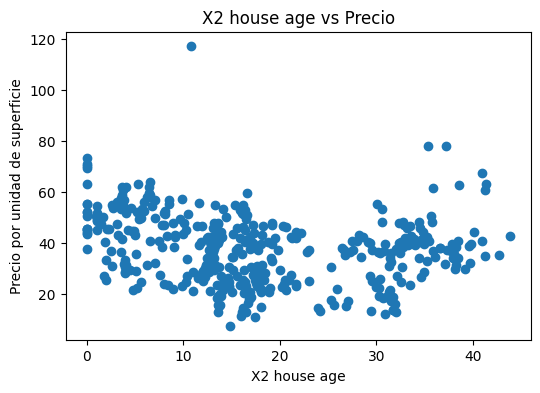

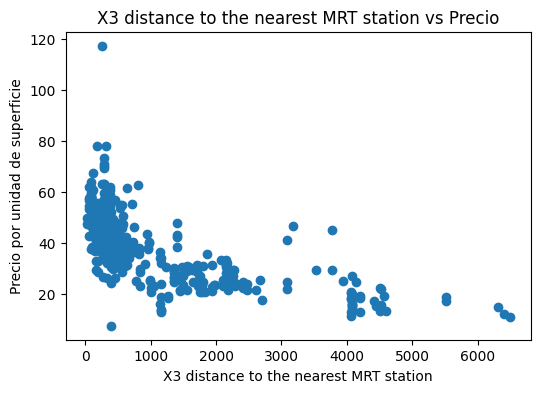

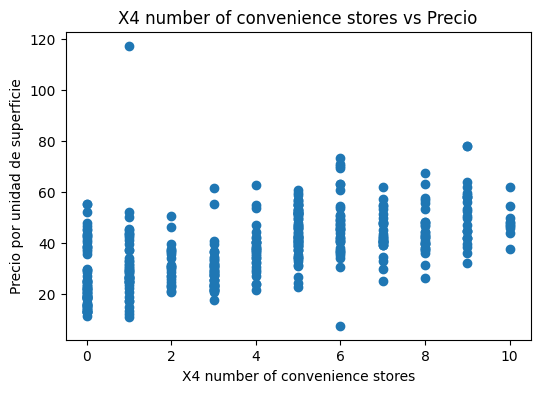

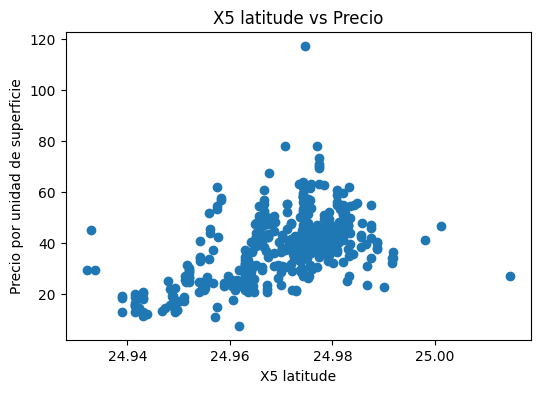

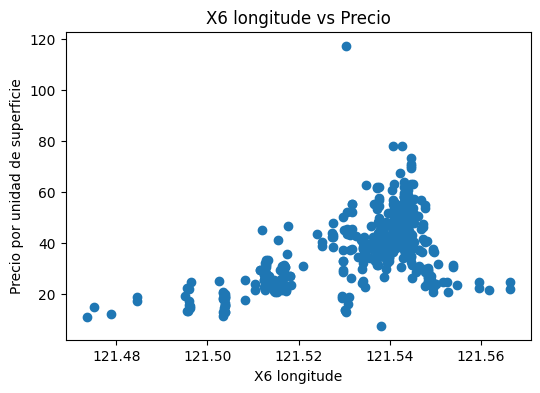

In [7]:
# Elegimos cinco columnas de X y dejamos afuera la fecha para enfocarnos en las características y la ubicación.
X = X[[
    'X2 house age',
    'X3 distance to the nearest MRT station',
    'X4 number of convenience stores',
    'X5 latitude',
    'X6 longitude'
]]

# Con iloc[:, 0] tomamos todas las filas de la primera columna de y y obtenemos una Serie.
precio = y.iloc[:, 0]

# Recorremos las columnas de X y hacemos un gráfico de dispersión por predictor.
for columna in X.columns:
    plt.figure(figsize=(6, 4))
    # Cada punto muestra el valor del predictor en el eje horizontal y el precio en el vertical.
    plt.scatter(X[columna], precio)
    plt.xlabel(columna)
    plt.ylabel('Precio por unidad de superficie')
    plt.title(f'{columna} vs Precio')
    plt.show()

### Conversión de datos a matrices de NumPy

In [8]:
# Convertimos los datos a arreglos de NumPy. X queda como matriz de 414 filas y 5 columnas.
X = X.to_numpy()
# Convertimos la Serie de precios a un vector con un valor por fila de X.
y = precio.to_numpy()

# Confirmamos que las dos estructuras contienen la misma cantidad de registros.
print("Dimensiones de X:", X.shape)
print("Dimensiones de Y:", y.shape)

Dimensiones de X: (414, 5)
Dimensiones de Y: (414,)


### Separación para entrenamiento y test

Separamos una parte para que el modelo aprenda y otra para comprobar cómo predice con datos que no utilizó durante el entrenamiento.

In [9]:
# Reservamos alrededor del 20 % para prueba y conservamos el precio asociado a cada fila de X.
# Fijamos random_state=42 para repetir la misma partición con los mismos datos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Verificamos que quedaron 331 filas en entrenamiento y 83 en prueba, ambas con cinco columnas.
print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (331, 5)
Datos de prueba: (83, 5)


De estas líneas de código obtenemos lo siguiente:


*   414 propiedades en total.
*   331 propiedades para entrenar el modelo.
*   83 propiedades reservadas para probarlo.
*   5 variables que utilizaremos para realizar las predicciones.





### Creación y entrenamiento del Modelo

In [10]:
# Creamos un modelo lineal que va a estimar un intercepto y un coeficiente por predictor.
modelo = LinearRegression()

# Ajustamos los coeficientes con los datos de entrenamiento, minimizando la suma de los errores al cuadrado.
modelo.fit(X_train, y_train)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


### Evaluación del modelo

In [11]:
# Usamos el modelo ajustado para predecir los precios en entrenamiento y en prueba.
predicciones_train = modelo.predict(X_train)
predicciones_test = modelo.predict(X_test)

# Calculamos R² comparando los precios reales con los estimados en cada conjunto. Un valor de 1 indica un ajuste perfecto.
r2_train = r2_score(y_train, predicciones_train)
r2_test = r2_score(y_test, predicciones_test)

# Calculamos el MSE, el promedio de los errores al cuadrado. Los errores grandes pesan más.
mse_train = mean_squared_error(y_train, predicciones_train)
mse_test = mean_squared_error(y_test, predicciones_test)

# Mostramos las métricas de los dos conjuntos para comparar el ajuste con el desempeño en datos reservados.
print("Resultados de entrenamiento:")
print("R²:", r2_train)
print("MSE:", mse_train)

print("\nResultados de prueba:")
print("R²:", r2_test)
print("MSE:", mse_test)

Resultados de entrenamiento:
R²: 0.5457883393347676
MSE: 85.43289947763142

Resultados de prueba:
R²: 0.6746481382828016
MSE: 54.58094520086482


## Comparación del desempeño

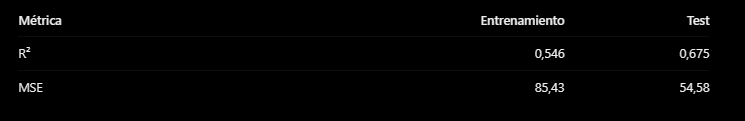

Estos números nos explican lo siguiente:



*   El R² de test es mayor que el de entrenamiento.
*   El MSE de test es menor, por lo que el error cuadrático medio también fue menor en ese conjunto.
*   Esto no significa necesariamente que haya un problema: puede ocurrir que los 83 registros de prueba sean más fáciles de predecir que los de entrenamiento.

En principio, no vemos una señal de sobreajuste en esta comparación. Pero tampoco podemos concluir que el modelo sea excelente: su capacidad predictiva es moderada y todavía tenemos que analizarlo.



### Analizamos los coeficientes del modelo

Queremos saber qué relación aprendió el modelo entre cada característica y el precio

In [12]:
# Armamos una tabla de coeficientes usando el mismo orden que en las columnas de X.
# Cada coeficiente indica cuánto cambia el precio estimado al subir un predictor una unidad y mantener fijos los demás.
coeficientes = pd.DataFrame({
    'Variable': [
        'Antigüedad',
        'Distancia al MRT',
        'Comercios cercanos',
        'Latitud',
        'Longitud'
    ],
    'Coeficiente': modelo.coef_
})

print(coeficientes)

# El intercepto es el valor que devuelve la ecuación cuando los cinco predictores valen cero.
print("\nIntersección (intercept):", modelo.intercept_)

             Variable  Coeficiente
0          Antigüedad    -0.270593
1    Distancia al MRT    -0.004552
2  Comercios cercanos     1.105121
3             Latitud   236.092831
4            Longitud   -23.903694

Intersección (intercept): -2946.6588590244473


In [13]:
# Sacamos la raíz cuadrada del MSE para expresar la magnitud del error en las mismas unidades que el precio.
rmse_train = np.sqrt(mse_train)
rmse_test = np.sqrt(mse_test)

print("RMSE entrenamiento:", rmse_train)
print("RMSE test:", rmse_test)

RMSE entrenamiento: 9.242991911585309
RMSE test: 7.387891796775642


### Interpretación de los coeficientes

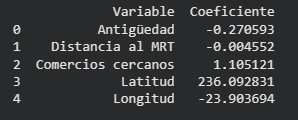

De estos resultados podemos identificar:

*   Antigüedad (-0,271): manteniendo las demás variables constantes, un año adicional de antigüedad se asocia con una disminución estimada de 0,271 unidades en el precio.

*   Distancia al MRT (-0,00455): a mayor distancia de la estación, menor precio estimado.

*  Comercios cercanos (+1,105): cada comercio adicional se asocia con un aumento estimado de 1,105 unidades.

*   Latitud (+236,093): tiene un coeficiente positivo.

*   Longitud (-23,904): tiene un coeficiente negativo.

Estos son efectos estimados por el modelo, no necesariamente relaciones causales.

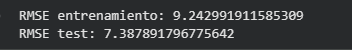


Por otro lado el RMSE nos indica que, en promedio y en términos de magnitud del error cuadrático, las predicciones se desvían aproximadamente 9,24 unidades en entrenamiento y 7,39 en test.

El resultado de test es mejor que el de entrenamiento. Es una buena señal para esta partición, aunque no garantiza que el modelo vaya a funcionar igual de bien con cualquier otro conjunto de propiedades.


Los coeficientes originales permiten observar la relación entre cada variable y el precio, manteniendo constantes las demás variables. Sin embargo, como las variables tienen diferentes unidades de medida, para comparar su influencia relativa calculamos también los coeficientes estandarizados.



### Cálculo de coeficientes estandarizados

In [14]:
# Con axis=0 calculamos un desvío estándar por columna usando las filas de entrenamiento.
desvio_X = np.std(X_train, axis=0)

# Calculamos el desvío estándar de los precios de entrenamiento.
desvio_y = np.std(y_train)

# Expresamos el cambio estimado en desvíos del precio por cada desvío del predictor, con las demás variables fijas.
coef_estandarizados = modelo.coef_ * desvio_X / desvio_y

# Armamos la tabla para comparar los valores absolutos y leer el sentido de la relación a partir del signo.
tabla_coef = pd.DataFrame({
    'Variable': [
        'Antigüedad',
        'Distancia al MRT',
        'Comercios cercanos',
        'Latitud',
        'Longitud'
    ],
    'Coeficiente estandarizado': coef_estandarizados
})

print(tabla_coef)

             Variable  Coeficiente estandarizado
0          Antigüedad                  -0.223153
1    Distancia al MRT                  -0.403674
2  Comercios cercanos                   0.237649
3             Latitud                   0.214588
4            Longitud                  -0.026062


### Comparación de predicciones

Cuanto más cerca estén los puntos de la línea roja, más cercanas serán las predicciones a los valores reales.

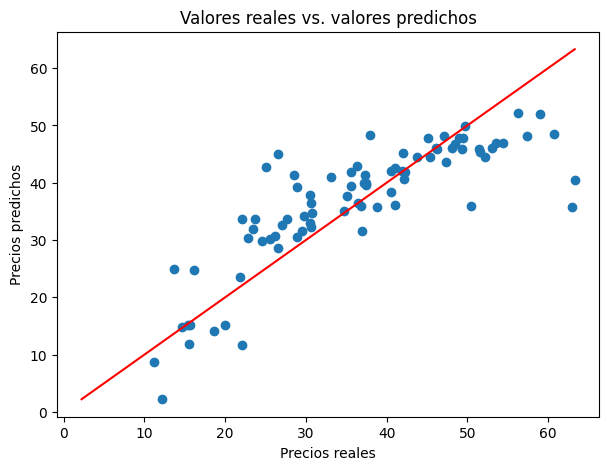

In [15]:
plt.figure(figsize=(7, 5))

# Cada punto compara el precio real de un registro de prueba con su precio predicho.
plt.scatter(y_test, predicciones_test)

plt.xlabel('Precios reales')
plt.ylabel('Precios predichos')
plt.title('Valores reales vs. valores predichos')

# Tomamos el mínimo y el máximo de los dos ejes para dibujar la diagonal de predicción perfecta.
limite_min = min(y_test.min(), predicciones_test.min())
limite_max = max(y_test.max(), predicciones_test.max())

# Encima de la diagonal el modelo sobreestima el precio y debajo lo subestima.
plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    color='red'
)

plt.show()

### Conclusiones

Se desarrolló un modelo de Regresión Lineal Múltiple utilizando el conjunto de datos Real Estate Valuation. Se seleccionaron cinco variables predictoras: antigüedad de la propiedad, distancia a la estación de MRT más cercana, cantidad de comercios cercanos, latitud y longitud. La variable objetivo fue el precio por unidad de superficie.

El modelo obtuvo un coeficiente de determinación (R²) de 0,546 en entrenamiento y 0,675 en prueba. Esto significa que, para el conjunto de prueba, el modelo logra explicar aproximadamente el 67,5 % de la variabilidad de los precios. El error cuadrático medio (MSE) fue de 85,43 en entrenamiento y 54,58 en prueba.

Al analizar los coeficientes estandarizados, se observa que la distancia a la estación de MRT es la variable con mayor influencia relativa, con un coeficiente de -0,404. Esto indica una relación negativa entre la distancia al transporte público y el precio de las propiedades. También se observa una relación negativa con la antigüedad y una relación positiva con la cantidad de comercios cercanos.

En cuanto a la capacidad predictiva, el gráfico de valores reales frente a valores predichos muestra que muchos puntos se encuentran próximos a la línea de referencia, lo que indica que las predicciones son razonablemente cercanas a los valores reales.

Al comparar entrenamiento y prueba, el rendimiento fue mejor en el conjunto de prueba. Esto no representa necesariamente un problema: puede deberse a que los datos de prueba seleccionados resultaron más sencillos de predecir. De todos modos, sería conveniente evaluar el modelo con otras particiones para comprobar la estabilidad de sus resultados.

Como conclusión, las variables seleccionadas aportan información útil para estimar el precio de las propiedades, aunque el modelo no explica toda su variabilidad. Se podrían obtener mejores resultados incorporando otras características, como la superficie del inmueble, su estado de conservación, la cantidad de habitaciones o las características del barrio.